In [1]:
# 1. Setup: point Spark to Hadoop winutils (Windows only, must run before Spark starts)
import os
if os.name == "nt":
    os.environ["HADOOP_HOME"] = r"C:\hadoop"
    os.environ["PATH"] += r";C:\hadoop\bin"

In [2]:
# 2. Setup: start the Spark session (4 cores, 4 GB driver memory)
from pyspark.sql import SparkSession, functions as F

spark = (
    SparkSession.builder
    .master("local[4]")
    .appName("medallion")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "16")
    .getOrCreate()
)

In [3]:
# 3. Bronze: read the raw CSV and inspect schema and sample rows
df = spark.read.csv("data/yellow_tripdata_2016-03.csv", header=True, inferSchema=True)
df.printSchema()
df.show(5)

root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp (nullable = true)
 |-- tpep_dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- pickup_longitude: double (nullable = true)
 |-- pickup_latitude: double (nullable = true)
 |-- RatecodeID: integer (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- dropoff_longitude: double (nullable = true)
 |-- dropoff_latitude: double (nullable = true)
 |-- payment_type: integer (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)

+--------+--------------------+---------------------+---------------+-------------+------------------+---------------

In [4]:
# 4. Bronze: save the raw data as Parquet, with no transformations
df.write.mode("overwrite").parquet("lake/bronze")

In [5]:
# 5. Bronze: read it back from disk and verify row count
bronze = spark.read.parquet("lake/bronze")
bronze.printSchema()
print(bronze.count())

root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp (nullable = true)
 |-- tpep_dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- pickup_longitude: double (nullable = true)
 |-- pickup_latitude: double (nullable = true)
 |-- RatecodeID: integer (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- dropoff_longitude: double (nullable = true)
 |-- dropoff_latitude: double (nullable = true)
 |-- payment_type: integer (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)

12210952


In [6]:
# 6. Silver: measure how many rows have data-quality problems (exploration only)
bronze.select(
    F.count("*").alias("total"),
    F.sum((F.col("fare_amount") <= 0).cast("int")).alias("fare_<=0"),
    F.sum((F.col("trip_distance") <= 0).cast("int")).alias("dist_<=0"),
    F.sum((F.col("passenger_count") <= 0).cast("int")).alias("pass_<=0"),
    F.sum((F.col("tpep_dropoff_datetime") <= F.col("tpep_pickup_datetime")).cast("int")).alias("bad_time"),
    F.sum((F.col("pickup_longitude") == 0).cast("int")).alias("lon_zero"),
).show()

+--------+--------+--------+--------+--------+--------+
|   total|fare_<=0|dist_<=0|pass_<=0|bad_time|lon_zero|
+--------+--------+--------+--------+--------+--------+
|12210952|    8362|   71126|     608|   14665|  182001|
+--------+--------+--------+--------+--------+--------+



In [7]:
# 7. Silver: clean the data (nulls, invalid values, out-of-range coordinates, duplicates) and save
silver = (
    bronze
    .dropna(subset=["tpep_pickup_datetime", "tpep_dropoff_datetime", "fare_amount"])
    .filter((F.col("fare_amount") > 0) & (F.col("fare_amount") < 500))
    .filter((F.col("trip_distance") > 0) & (F.col("trip_distance") < 100))
    .filter(F.col("passenger_count").between(1, 6))
    .filter(F.col("tpep_dropoff_datetime") > F.col("tpep_pickup_datetime"))
    .filter(F.col("pickup_longitude").between(-74.3, -73.7))
    .filter(F.col("pickup_latitude").between(40.5, 41.0))
    .filter(F.col("dropoff_longitude").between(-74.3, -73.7))
    .filter(F.col("dropoff_latitude").between(40.5, 41.0))
    .dropDuplicates()
)

silver.write.mode("overwrite").parquet("lake/silver")

In [8]:
# 8. Silver: validate by comparing row counts before and after cleaning
silver = spark.read.parquet("lake/silver")
n_bronze = bronze.count()
n_silver = silver.count()
print("bronze:", n_bronze)
print("silver:", n_silver)
print("dropped:", n_bronze - n_silver, f"({(n_bronze - n_silver) / n_bronze:.1%})")

bronze: 12210952
silver: 11951380
dropped: 259572 (2.1%)


In [9]:
# 9. Silver: check summary statistics to confirm values are now realistic
silver.select("tpep_pickup_datetime", "trip_distance", "fare_amount", "passenger_count").describe().show()

+-------+-----------------+------------------+------------------+
|summary|    trip_distance|       fare_amount|   passenger_count|
+-------+-----------------+------------------+------------------+
|  count|         11951380|          11951380|          11951380|
|   mean|2.958462226956073|12.654862446010435|1.6641366938378663|
| stddev|3.569488181982097|10.263076341669871|1.3168361140641913|
|    min|             0.01|              0.01|                 1|
|    max|            95.74|            450.01|                 6|
+-------+-----------------+------------------+------------------+



In [10]:
# 10. Gold: add derived columns (duration, speed, hour, weekday, tip %) and drop impossible trips
silver = spark.read.parquet("lake/silver")

enriched = (
    silver
    .withColumn("duration_min",
        (F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")) / 60)
    .withColumn("speed_mph", F.col("trip_distance") / (F.col("duration_min") / 60))
    .withColumn("pickup_hour", F.hour("tpep_pickup_datetime"))
    .withColumn("pickup_dow", F.dayofweek("tpep_pickup_datetime"))
    .withColumn("is_weekend", F.col("pickup_dow").isin(1, 7))
    .withColumn("price_per_mile", F.col("fare_amount") / F.col("trip_distance"))
    .withColumn("tip_pct",
        F.when(F.col("payment_type") == 1, F.col("tip_amount") / F.col("fare_amount") * 100))
    .filter(F.col("duration_min").between(1, 180))
    .filter(F.col("speed_mph") < 80)
)

In [11]:
# 11. Gold: join with a payment-type lookup table and save the enriched trips
payment_types = spark.createDataFrame(
    [(1, "Credit card"), (2, "Cash"), (3, "No charge"), (4, "Dispute"), (5, "Unknown"), (6, "Voided trip")],
    ["payment_type", "payment_name"],
)

gold_trips = enriched.join(payment_types, on="payment_type", how="left")
gold_trips.write.mode("overwrite").parquet("lake/gold/trips")

In [12]:
# 12. Gold: aggregate trips, fare, duration and speed by hour of day and save
gold_trips = spark.read.parquet("lake/gold/trips")

by_hour = (
    gold_trips
    .groupBy("pickup_hour")
    .agg(
        F.count("*").alias("trips"),
        F.round(F.avg("fare_amount"), 2).alias("avg_fare"),
        F.round(F.avg("duration_min"), 1).alias("avg_duration_min"),
        F.round(F.avg("speed_mph"), 1).alias("avg_speed_mph"),
    )
    .orderBy("pickup_hour")
)

by_hour.show(24)
by_hour.write.mode("overwrite").parquet("lake/gold/by_hour")

+-----------+------+--------+----------------+-------------+
|pickup_hour| trips|avg_fare|avg_duration_min|avg_speed_mph|
+-----------+------+--------+----------------+-------------+
|          0|417764|   13.28|            12.8|         14.9|
|          1|298933|   12.77|            12.8|         15.2|
|          2|201380|   12.53|            11.6|         15.8|
|          3|151690|   13.09|            11.8|         16.4|
|          4|133193|   14.83|            12.2|         18.5|
|          5|120910|   15.87|            11.9|         20.1|
|          6|269119|   13.11|            11.4|         16.5|
|          7|458286|   11.92|            12.5|         12.8|
|          8|560081|   12.05|            13.8|         10.7|
|          9|558421|   12.08|            14.0|         10.4|
|         10|535714|    12.3|            14.0|         10.6|
|         11|548452|   12.43|            14.2|         10.4|
|         12|574914|   12.46|            14.2|         10.3|
|         13|576147|   1

In [13]:
# 13. Gold: trip count and average tip percentage by payment type
(gold_trips
    .groupBy("payment_name")
    .agg(F.count("*").alias("trips"), F.round(F.avg("tip_pct"), 1).alias("avg_tip_pct"))
    .orderBy(F.desc("trips"))
    .show())

+------------+-------+-----------+
|payment_name|  trips|avg_tip_pct|
+------------+-------+-----------+
| Credit card|7958750|       22.3|
|        Cash|3895291|       NULL|
|   No charge|  30540|       NULL|
|     Dispute|  12042|       NULL|
+------------+-------+-----------+



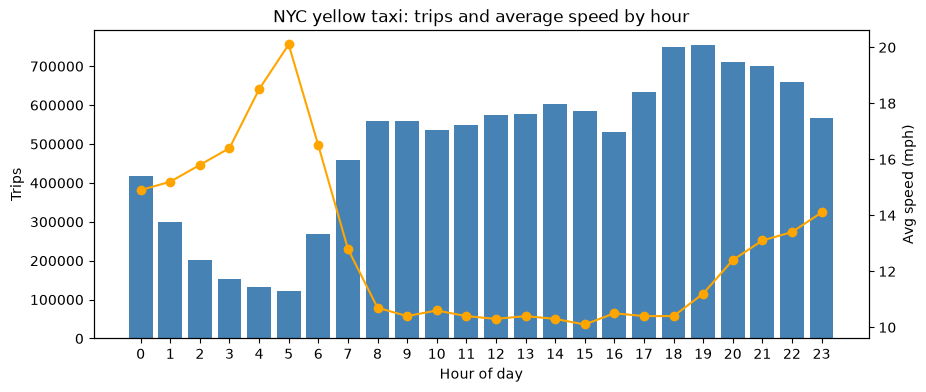

In [14]:
# 14. Chart: trips (bars) and average speed (line) by hour of day
import matplotlib.pyplot as plt

rows = spark.read.parquet("lake/gold/by_hour").orderBy("pickup_hour").collect()
hours = [r["pickup_hour"] for r in rows]
trips = [r["trips"] for r in rows]
speed = [r["avg_speed_mph"] for r in rows]

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(hours, trips, color="steelblue")
ax1.set_xlabel("Hour of day")
ax1.set_ylabel("Trips")
ax1.set_xticks(range(24))

ax2 = ax1.twinx()
ax2.plot(hours, speed, color="orange", marker="o")
ax2.set_ylabel("Avg speed (mph)")

plt.title("NYC yellow taxi: trips and average speed by hour")
plt.savefig("hourly_trips_speed.png", dpi=150, bbox_inches="tight")
plt.show()